CWD: c:\Users\abdou\Desktop\Projets_Data\energy-monitoring-platform\notebooks
PROJECT ROOT: C:\Users\abdou\Desktop\Projets_Data\energy-monitoring-platform
SRC EXISTS: True


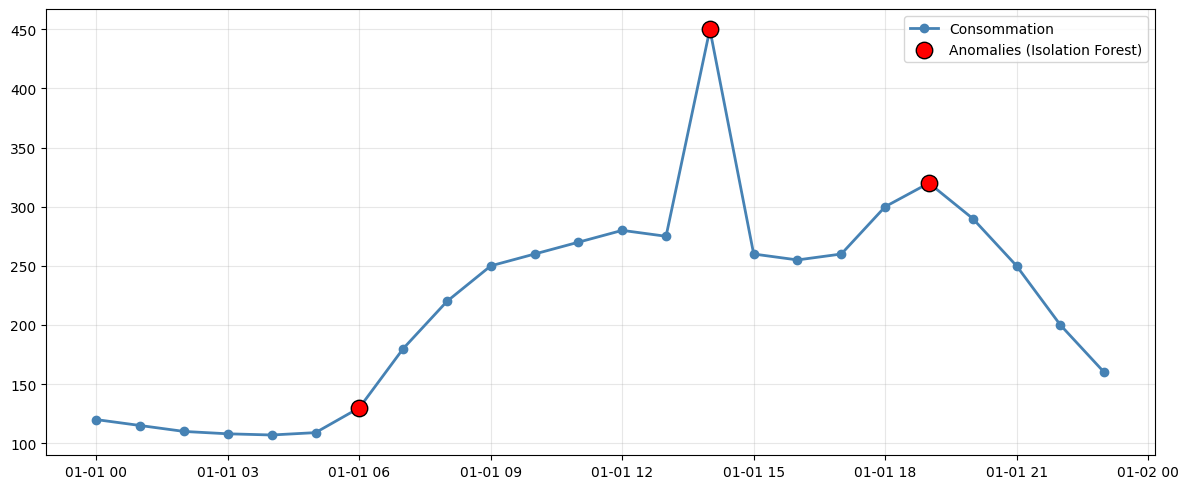

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve()
while project_root != project_root.parent and not (project_root / "src").exists():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

print("CWD:", Path.cwd())
print("PROJECT ROOT:", project_root)
print("SRC EXISTS:", (project_root / "src").exists())

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
import importlib
import src.detection.anomaly_detection as ad
importlib.reload(ad)


from src.preprocessing import preprocess_energy_data
from src.detection import (
    detect_rolling_anomalies,
    detect_isolation_forest,
)

data = {
    "timestamp": [
        "2024-01-01 00:00", "2024-01-01 01:00", "2024-01-01 02:00",
        "2024-01-01 03:00", "2024-01-01 04:00", "2024-01-01 05:00",
        "2024-01-01 06:00", "2024-01-01 07:00", "2024-01-01 08:00",
        "2024-01-01 09:00", "2024-01-01 10:00", "2024-01-01 11:00",
        "2024-01-01 12:00", "2024-01-01 13:00", "2024-01-01 14:00",
        "2024-01-01 15:00", "2024-01-01 16:00", "2024-01-01 17:00",
        "2024-01-01 18:00", "2024-01-01 19:00", "2024-01-01 20:00",
        "2024-01-01 21:00", "2024-01-01 22:00", "2024-01-01 23:00"
    ],
    "energy_kwh": [
        120, 115, 110, 108, 107, 109,
        130, 180, 220, 250, 260, 270,
        280, 275, 450, 260, 255, 260,
        300, 320, 290, 250, 200, 160
    ]
}

df = pd.DataFrame(data)
df = preprocess_energy_data(df)
df = detect_rolling_anomalies(df, window_size=3, threshold=2)
df = detect_isolation_forest(df, features=["energy_kwh"])

df["is_anomaly_iforest"].value_counts()


df[[
    "timestamp",
    "energy_kwh",
    "is_anomaly_rolling",
    "is_anomaly_iforest"
]]

plt.figure(figsize=(12, 5))

# Courbe principale
plt.plot(
    df["timestamp"],
    df["energy_kwh"],
    color="steelblue",
    linewidth=2,
    marker="o",
    label="Consommation"
)

# Anomalies Isolation Forest
anoms = df[df["is_anomaly_iforest"]]

plt.scatter(
    anoms["timestamp"],
    anoms["energy_kwh"],
    color="red",
    s=140,                 # taille grosse
    zorder=10,             # AU-DESSUS de tout
    edgecolors="black",    # contour visible
    label="Anomalies (Isolation Forest)"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

